In [18]:
import torch
import torch.nn as nn
torch.manual_seed(42)

# --------------------------------------------------
# 1. Créer les données
# --------------------------------------------------
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)
longueur_sequence = 10
# Chaque entrée contient 10 valeurs.
# La cible est la valeur immédiatement suivante.
X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
# Un RNN attend : (nombre de séquences, longueur, nombre de variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique : début pour apprendre, fin pour tester.
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

Text(0, 0.5, 'y')

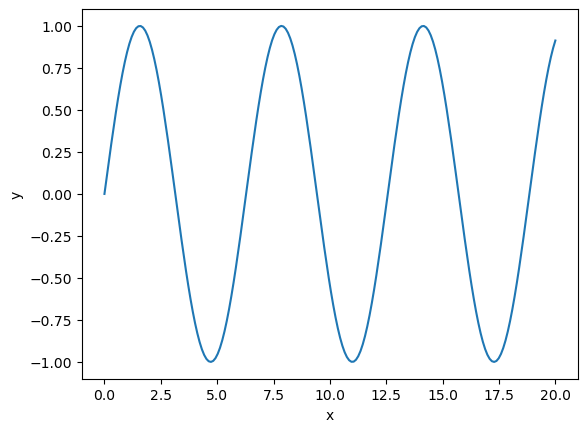

In [19]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
plt.plot(periode, serie)
plt.xlabel("x")
plt.ylabel("y")

In [20]:
# --------------------------------------------------
# 2. Définir le modèle
# --------------------------------------------------

class SimpleRNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.rnn = nn.RNN(
            input_size=1,     # Une valeur à chaque instant
            hidden_size=16,   # Une mémoire composée de 16 nombres
            batch_first=True
        )

        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        # Si aucun état initial n'est fourni, PyTorch utilise des zéros.
        etats, _ = self.rnn(x)

        # etats : (nombre de séquences, 10, 16)
        dernier_etat = etats[:, -1, :]  # (nombre de séquences, 16)

        # Transformer la mémoire finale en une valeur prédite.
        return self.sortie(dernier_etat)


modele = SimpleRNN()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)

In [21]:
# --------------------------------------------------
# 3. Entraîner le modèle
# --------------------------------------------------

modele.train()

for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()  # Effacer les anciens gradients
    perte.backward()       # Calculer les nouveaux gradients
    optimiseur.step()      # Mettre à jour les paramètres

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")


# --------------------------------------------------
# 4. Tester le modèle
# --------------------------------------------------

modele.eval()

with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.001277
Epoch 100 | Erreur : 0.000504
Epoch 150 | Erreur : 0.000223
Epoch 200 | Erreur : 0.000103
Epoch 250 | Erreur : 0.000049
Epoch 300 | Erreur : 0.000025

Erreur de test : 0.000028
Valeur réelle  : -0.3639
Valeur prédite : -0.3601


In [22]:
predictions.shape

torch.Size([40, 1])

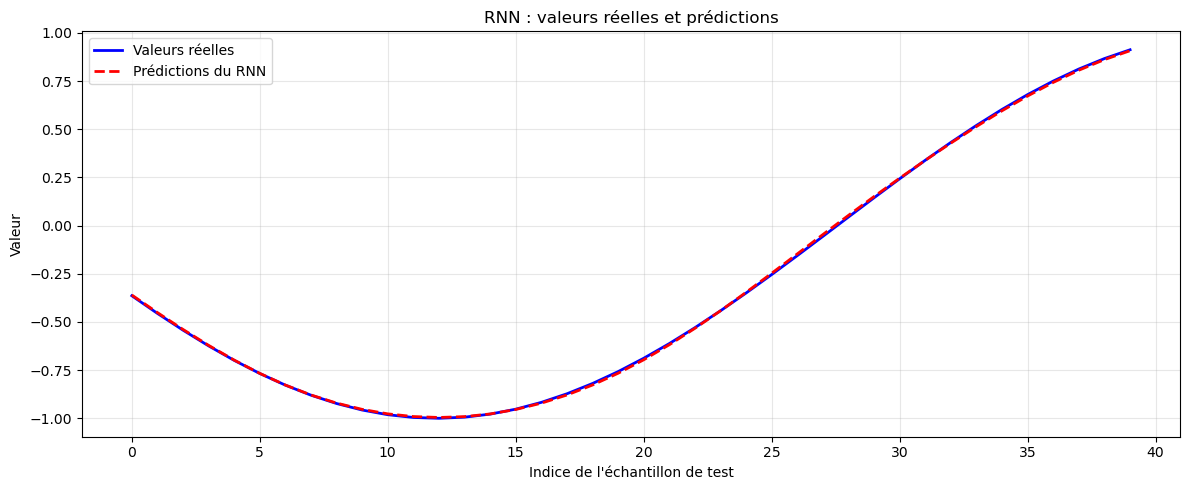

In [23]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites,
    label="Prédictions du RNN",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("RNN : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [24]:
import torch
import torch.nn as nn

torch.manual_seed(42)

# --------------------------------------------------
# 1. Créer les données
# --------------------------------------------------

serie = torch.sin(torch.linspace(0, 20, 200))
longueur_sequence = 10

X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

# Forme attendue : (nombre de séquences, longueur, variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]


# --------------------------------------------------
# 2. Définir le modèle LSTM
# --------------------------------------------------

class SimpleLSTM(nn.Module):
    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,     # Une variable à chaque instant
            hidden_size=16,   # 16 unités cachées
            num_layers=1,     # Une seule couche LSTM
            batch_first=True
        )

        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        # Sans états initiaux fournis, h₀ et c₀ sont mis à zéro.
        etats, (h_final, c_final) = self.lstm(x)

        # etats : (nombre de séquences, 10, 16)
        dernier_etat = etats[:, -1, :]  # (nombre de séquences, 16)

        # Une prédiction par séquence
        return self.sortie(dernier_etat)


modele = SimpleLSTM()
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)


# --------------------------------------------------
# 3. Entraîner le modèle
# --------------------------------------------------

modele.train()

for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")


# --------------------------------------------------
# 4. Tester le modèle
# --------------------------------------------------

modele.eval()

with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.003562
Epoch 100 | Erreur : 0.000248
Epoch 150 | Erreur : 0.000043
Epoch 200 | Erreur : 0.000006
Epoch 250 | Erreur : 0.000004
Epoch 300 | Erreur : 0.000003

Erreur de test : 0.000003
Valeur réelle  : -0.3639
Valeur prédite : -0.3622


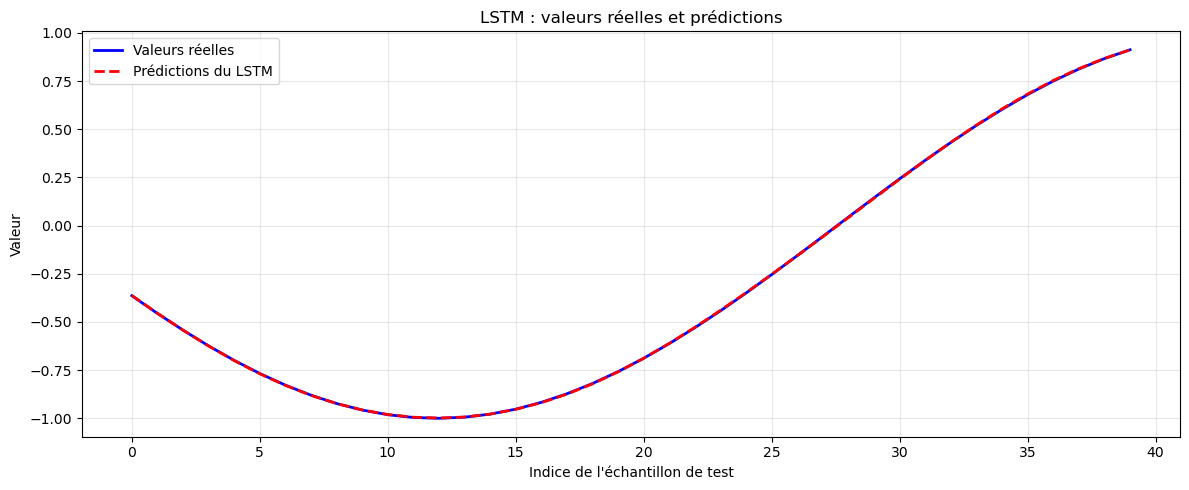

In [25]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites,
    label="Prédictions du LSTM",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("LSTM : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
import torch
import torch.nn as nn

torch.manual_seed(42)

# --------------------------------------------------
# 1. Créer les données
# --------------------------------------------------

serie = torch.sin(torch.linspace(0, 20, 200))
longueur_sequence = 10

X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

# Forme : (nombre de séquences, longueur, variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]


# --------------------------------------------------
# 2. Définir le modèle Transformer
# --------------------------------------------------

class MiniTransformer(nn.Module):
    def __init__(self, longueur_max=10):
        super().__init__()

        dimension = 16

        # Transformer chaque valeur en un vecteur de 16 nombres.
        self.projection = nn.Linear(1, dimension)

        # Un vecteur appris pour chacune des 10 positions.
        self.positions = nn.Embedding(longueur_max, dimension)

        # Un bloc d'encodeur Transformer.
        couche = nn.TransformerEncoderLayer(
            d_model=dimension,       # Taille des représentations : 16
            nhead=2,                 # Deux têtes d'attention
            dim_feedforward=32,      # Taille interne du réseau feed-forward
            dropout=0.0,             # Désactivé pour simplifier l'exemple
            batch_first=True
        )

        self.encodeur = nn.TransformerEncoder(
            couche,
            num_layers=1
        )

        # Transformer la représentation finale en une prédiction.
        self.sortie = nn.Linear(dimension, 1)

    def forward(self, x):
        # x : (B, 10, 1)
        longueur = x.size(1)

        # 1. Projection des valeurs
        x = self.projection(x)  # (B, 10, 16)

        # 2. Ajout de l'information de position
        indices = torch.arange(longueur, device=x.device)
        positions = self.positions(indices)  # (10, 16)

        x = x + positions.unsqueeze(0)  # (B, 10, 16)

        # 3. Mise en relation des valeurs par auto-attention
        representations = self.encodeur(x)  # (B, 10, 16)

        # 4. Récupérer la représentation de la dernière position
        derniere_position = representations[:, -1, :]  # (B, 16)

        # 5. Prédire la valeur suivante
        return self.sortie(derniere_position)  # (B, 1)


modele = MiniTransformer(longueur_max=longueur_sequence)
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=0.01)


# --------------------------------------------------
# 3. Entraîner le modèle
# --------------------------------------------------

modele.train()

for epoch in range(300):
    predictions = modele(X_train)
    perte = critere(predictions, y_train)

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if (epoch + 1) % 50 == 0:
        print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")


# --------------------------------------------------
# 4. Tester le modèle
# --------------------------------------------------

modele.eval()

with torch.no_grad():
    predictions = modele(X_test)
    erreur_test = critere(predictions, y_test)

print(f"\nErreur de test : {erreur_test.item():.6f}")
print(f"Valeur réelle  : {y_test[0].item():.4f}")
print(f"Valeur prédite : {predictions[0].item():.4f}")

Epoch  50 | Erreur : 0.001504
Epoch 100 | Erreur : 0.000110
Epoch 150 | Erreur : 0.000026
Epoch 200 | Erreur : 0.000012
Epoch 250 | Erreur : 0.000007
Epoch 300 | Erreur : 0.000004

Erreur de test : 0.000006
Valeur réelle  : -0.3639
Valeur prédite : -0.3662


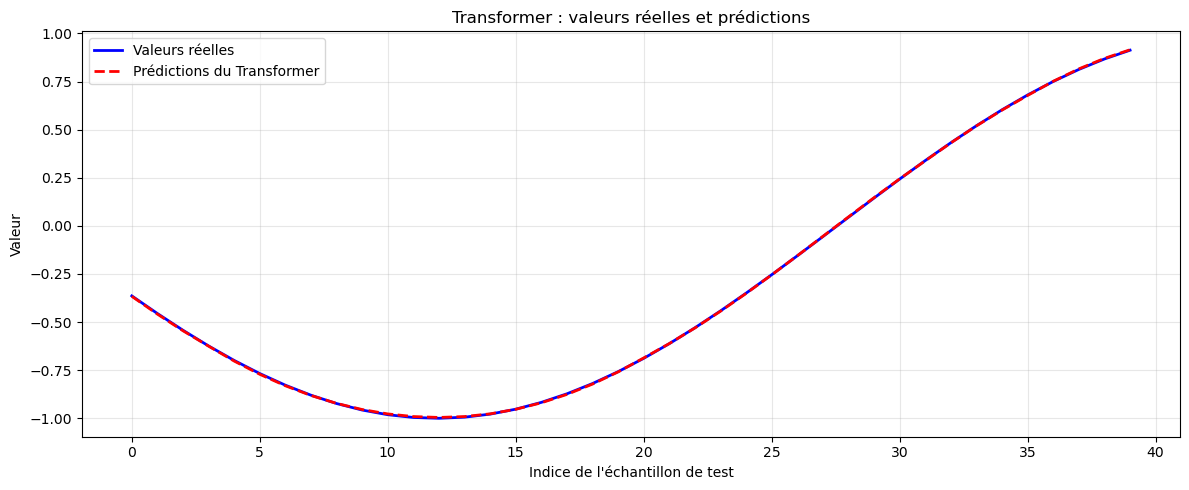

In [27]:
import matplotlib.pyplot as plt

# Convertir les tenseurs en tableaux NumPy
valeurs_reelles = y_test.detach().cpu().numpy().reshape(-1)
valeurs_predites = predictions.detach().cpu().numpy().reshape(-1)

# Tracer les deux courbes
plt.figure(figsize=(12, 5))

plt.plot(
    valeurs_reelles,
    label="Valeurs réelles",
    color="blue",
    linewidth=2
)

plt.plot(
    valeurs_predites,
    label="Prédictions du Transformer",
    color="red",
    linestyle="--",
    linewidth=2
)

plt.title("Transformer : valeurs réelles et prédictions")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("Valeur")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

# --------------------------------------------------
# 1. Charger le tokenizer et le modèle préentraîné
# --------------------------------------------------

nom_modele = "gpt2"

tokenizer = AutoTokenizer.from_pretrained(nom_modele)
modele = AutoModelForCausalLM.from_pretrained(nom_modele)

# GPT-2 ne possède pas de token de padding dédié.
tokenizer.pad_token = tokenizer.eos_token
modele.config.pad_token_id = tokenizer.pad_token_id

modele.eval()

# --------------------------------------------------
# 2. Transformer le texte en tokens
# --------------------------------------------------

# GPT-2 est principalement entraîné sur de l'anglais.
texte = "Artificial intelligence can help people"

entrees = tokenizer(
    texte,
    return_tensors="pt"
)

print("Dimensions de l'entrée :", entrees["input_ids"].shape)
# (1, nombre de tokens du texte)

# --------------------------------------------------
# 3. Générer la suite, un token après l'autre
# --------------------------------------------------

with torch.no_grad():
    sortie = modele.generate(
        **entrees,
        max_new_tokens=50,       # Générer au maximum 50 tokens
        do_sample=True,          # Tirage aléatoire des tokens
        temperature=0.8,         # Contrôler la diversité
        top_p=0.9,               # Limiter les candidats probables
        pad_token_id=tokenizer.pad_token_id
    )

# --------------------------------------------------
# 4. Reconvertir les tokens en texte
# --------------------------------------------------

texte_genere = tokenizer.decode(
    sortie[0],
    skip_special_tokens=True
)

print("\nTexte généré :")
print(texte_genere)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Dimensions de l'entrée : torch.Size([1, 6])

Texte généré :
Artificial intelligence can help people and organizations create jobs and build organizations, which in turn will spur growth and prosperity.

However, when a company becomes more complex, it's likely that its users will be less interested in technology. The companies that make the software that makes things


In [29]:
# ==================================================
# 0. Mode hors ligne automatique si Hugging Face est injoignable
#    (à exécuter juste après un redémarrage du kernel)
# ==================================================
import os
import socket

def hub_joignable(hote="huggingface.co", port=443, delai=3):
    try:
        socket.create_connection((hote, port), timeout=delai).close()
        return True
    except OSError:
        return False

if not hub_joignable():
    os.environ["HF_HUB_OFFLINE"] = "1"
    os.environ["TRANSFORMERS_OFFLINE"] = "1"
    print("huggingface.co injoignable -> chargement depuis le cache local\n")

import torch
from transformers import AutoTokenizer, AutoModelForMaskedLM

# --------------------------------------------------
# 1. Charger le tokenizer et le modèle préentraîné
# --------------------------------------------------
nom_modele = "bert-base-multilingual-cased"

tokenizer = AutoTokenizer.from_pretrained(nom_modele)
modele = AutoModelForMaskedLM.from_pretrained(nom_modele)
modele.eval()

# --------------------------------------------------
# 2. Préparer un texte avec un token masqué
# --------------------------------------------------
texte = f"Rabat est la {tokenizer.mask_token} du Maroc."

entrees = tokenizer(texte, return_tensors="pt")

print("Texte :", texte)
print("Dimensions de l'entrée :", entrees["input_ids"].shape)

position_masque = (
    entrees["input_ids"][0] == tokenizer.mask_token_id
).nonzero(as_tuple=True)[0].item()

# --------------------------------------------------
# 3. Prédire le token masqué
# --------------------------------------------------
with torch.no_grad():
    sortie = modele(**entrees)

scores = sortie.logits[0, position_masque, :]
probabilites = torch.softmax(scores, dim=-1)
top_probabilites, top_indices = torch.topk(probabilites, k=5)

# --------------------------------------------------
# 4. Afficher les propositions
# --------------------------------------------------
print("\nPropositions de BERT :")
for probabilite, indice in zip(top_probabilites, top_indices):
    token = tokenizer.decode([indice.item()]).strip()
    phrase = texte.replace(tokenizer.mask_token, token)
    print(f"{probabilite.item():.2%} | {phrase}")

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

BertForMaskedLM LOAD REPORT from: bert-base-multilingual-cased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Texte : Rabat est la [MASK] du Maroc.
Dimensions de l'entrée : torch.Size([1, 9])

Propositions de BERT :
86.06% | Rabat est la capitale du Maroc.
5.19% | Rabat est la ville du Maroc.
5.03% | Rabat est la préfecture du Maroc.
0.85% | Rabat est la Rabat du Maroc.
0.58% | Rabat est la capital du Maroc.


In [30]:
import torch
from transformers import AutoTokenizer, AutoModelForMaskedLM

# --------------------------------------------------
# 1. Charger le tokenizer et le modèle préentraîné
# --------------------------------------------------

nom_modele = "bert-base-multilingual-cased"

tokenizer = AutoTokenizer.from_pretrained(nom_modele)
modele = AutoModelForMaskedLM.from_pretrained(nom_modele)

modele.eval()

# --------------------------------------------------
# 2. Préparer un texte avec un token masqué
# --------------------------------------------------

texte = f"Rabat est la {tokenizer.mask_token} Maroc."

entrees = tokenizer(
    texte,
    return_tensors="pt"
)

print("Texte :", texte)
print("Dimensions de l'entrée :", entrees["input_ids"].shape)
# (1, nombre de tokens du texte)

# Repérer la position du masque dans la séquence
position_masque = (
    entrees["input_ids"][0] == tokenizer.mask_token_id
).nonzero(as_tuple=True)[0].item()

# --------------------------------------------------
# 3. Prédire le token masqué
# --------------------------------------------------

with torch.no_grad():
    sortie = modele(**entrees)

# sortie.logits : (1, nombre de tokens, taille du vocabulaire)
scores = sortie.logits[0, position_masque, :]

# Transformer les scores en probabilités
probabilites = torch.softmax(scores, dim=-1)

# Sélectionner les 5 tokens les plus probables
top_probabilites, top_indices = torch.topk(probabilites, k=5)

# --------------------------------------------------
# 4. Afficher les propositions
# --------------------------------------------------

print("\nPropositions de BERT :")

for probabilite, indice in zip(top_probabilites, top_indices):
    token = tokenizer.decode([indice.item()]).strip()

    phrase = texte.replace(tokenizer.mask_token, token)

    print(f"{probabilite.item():.2%} | {phrase}")

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

BertForMaskedLM LOAD REPORT from: bert-base-multilingual-cased
Key                         | Status     |  | 
----------------------------+------------+--+-
bert.pooler.dense.bias      | UNEXPECTED |  | 
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Texte : Rabat est la [MASK] Maroc.
Dimensions de l'entrée : torch.Size([1, 8])

Propositions de BERT :
42.90% | Rabat est la capitale Maroc.
20.66% | Rabat est la du Maroc.
6.23% | Rabat est la de Maroc.
3.46% | Rabat est la ville Maroc.
1.67% | Rabat est la Rabat Maroc.


1. Implémenter un bloc GPT contenant :
   - une normalisation LayerNorm avant l’attention ;
   - une attention multi-têtes causale ;
   - une connexion résiduelle ;
   - une seconde normalisation ;
   - un MLP 64 → 256 → 64, avec activation GELU ;
   - une seconde connexion résiduelle.

In [31]:
import torch
import torch.nn as nn
import numpy as np


class EnergyTransformer(nn.Module):
    def __init__(self, seq_len=24, d_model=32, nhead=4, num_layers=2,
                 dim_feedforward=128, dropout=0.1):
        super().__init__()
        self.seq_len = seq_len
        self.d_model = d_model

        # 1) Projection d'entrée : (batch, 24, 1) -> (batch, 24, 32)
        self.input_proj = nn.Linear(1, d_model)

        # 2) Encodage positionnel (paramètre appris) pour les 24 heures
        self.pos_embedding = nn.Parameter(torch.zeros(1, seq_len, d_model))
        nn.init.trunc_normal_(self.pos_embedding, std=0.02)

        # 3) Deux couches TransformerEncoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
        )
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

        # 4) Tête de sortie sur la dernière heure : (batch, 32) -> (batch, 1)
        self.output_proj = nn.Linear(d_model, 1)

    def forward(self, x):
        # x : (batch, 24, 1)
        x = self.input_proj(x)                 # (batch, 24, 32)
        x = x + self.pos_embedding             # ajout encodage positionnel
        x = self.transformer(x)                # (batch, 24, 32)
        x = x[:, -1, :]                        # dernière heure -> (batch, 32)
        return self.output_proj(x)             # (batch, 1)

# Exercices — Architecture Transformer

## Exercice 1 — Prédiction de la consommation électrique avec un Transformer

Objectif : utiliser les 24 dernières heures de `Global_active_power` (moyenne horaire, en kW) pour prédire l'heure suivante.

> Le fichier `household_power_consumption.txt` (UCI) doit se trouver dans le même dossier que le notebook.

In [32]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

Device : cuda


### 1. Préparation des données

In [33]:
df = pd.read_csv(
    "household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False,
)

df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
)

puissance = pd.to_numeric(df["Global_active_power"], errors="coerce")
puissance.index = pd.DatetimeIndex(df["datetime"])

# Puissance moyenne horaire : conserver les heures suffisamment renseignées.
horaire = puissance.resample("h").agg(["mean", "count"])
serie = horaire["mean"].where(horaire["count"] >= 45)

# Découpage chronologique : 70 % entraînement, 15 % validation, 15 % test.
n = len(serie)
fin_train = int(0.70 * n)
fin_val = int(0.85 * n)

# Normalisation calculée uniquement sur l'entraînement.
moyenne = serie.iloc[:fin_train].mean()
ecart_type = serie.iloc[:fin_train].std()
valeurs = ((serie - moyenne) / ecart_type).to_numpy()

# Une entrée contient 24 heures consécutives.
# Écarter les fenêtres comportant des valeurs manquantes.
fenetre = 24
X, y, dates_cibles = [], [], []

for i in range(fenetre, n):
    sequence = valeurs[i - fenetre:i]
    cible = valeurs[i]

    if np.isfinite(sequence).all() and np.isfinite(cible):
        X.append(sequence)
        y.append(cible)
        dates_cibles.append(i)

X = torch.tensor(np.array(X), dtype=torch.float32).unsqueeze(-1)   # (N, 24, 1)
y = torch.tensor(np.array(y), dtype=torch.float32).unsqueeze(-1)   # (N, 1)
dates_cibles = np.array(dates_cibles)

train_mask = torch.as_tensor(dates_cibles < fin_train)
val_mask = torch.as_tensor((dates_cibles >= fin_train) & (dates_cibles < fin_val))
test_mask = torch.as_tensor(dates_cibles >= fin_val)

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

# Horodatage de chaque heure cible du test (pour le graphique)
temps_test = serie.index[dates_cibles[test_mask.numpy()]]

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=64)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=64)

print(f"Moyenne (train)    : {moyenne:.4f} kW")
print(f"Écart-type (train) : {ecart_type:.4f} kW")
print("Train :", tuple(X_train.shape), tuple(y_train.shape))
print("Val   :", tuple(X_val.shape), tuple(y_val.shape))
print("Test  :", tuple(X_test.shape), tuple(y_test.shape))

Moyenne (train)    : 1.0865 kW
Écart-type (train) : 0.9287 kW
Train : (23805, 24, 1) (23805, 1)
Val   : (5054, 24, 1) (5054, 1)
Test  : (4932, 24, 1) (4932, 1)


### 2. Modèle `EnergyTransformer`

In [34]:
class EnergyTransformer(nn.Module):
    def __init__(self, longueur=24, d_model=32, nhead=4, dim_feedforward=128,
                 dropout=0.1, nb_couches=2):
        super().__init__()

        # Projection : une valeur -> un vecteur de 32 nombres
        self.projection = nn.Linear(1, d_model)

        # Encodage positionnel appris : un vecteur par heure (24 positions)
        self.positions = nn.Embedding(longueur, d_model)

        # Deux couches d'encodeur Transformer
        couche = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(
            couche, num_layers=nb_couches, enable_nested_tensor=False
        )

        # Tête de prédiction appliquée à la dernière heure
        self.sortie = nn.Linear(d_model, 1)

    def forward(self, x, afficher_formes=False):
        # x : (batch, 24, 1)
        indices = torch.arange(x.size(1), device=x.device)

        h = self.projection(x)                              # (batch, 24, 32)
        if afficher_formes:
            print("Après projection          :", tuple(h.shape))

        h = h + self.positions(indices).unsqueeze(0)        # (batch, 24, 32)
        h = self.encodeur(h)                                # (batch, 24, 32)
        if afficher_formes:
            print("Après Transformer Encoder :", tuple(h.shape))

        prediction = self.sortie(h[:, -1, :])               # (batch, 1)
        if afficher_formes:
            print("Prédiction                :", tuple(prediction.shape))
        return prediction


modele_energie = EnergyTransformer().to(device)

# Vérification des formes sur un lot
xb, _ = next(iter(train_loader))
print("Entrée                    :", tuple(xb.shape))
with torch.no_grad():
    modele_energie(xb.to(device), afficher_formes=True)

print("\nNombre de paramètres :", sum(p.numel() for p in modele_energie.parameters()))

Entrée                    : (64, 24, 1)
Après projection          : (64, 24, 32)
Après Transformer Encoder : (64, 24, 32)
Prédiction                : (64, 1)

Nombre de paramètres : 26273


### 3. Entraînement (Adam, lr = 0.001, MSE, 20 époques max, meilleur modèle en validation)

Époque  1 | train MSE = 0.4700 | val MSE = 0.4069  <- meilleur
Époque  2 | train MSE = 0.4290 | val MSE = 0.3925  <- meilleur
Époque  3 | train MSE = 0.4216 | val MSE = 0.3960
Époque  4 | train MSE = 0.4190 | val MSE = 0.4038
Époque  5 | train MSE = 0.4162 | val MSE = 0.3957
Époque  6 | train MSE = 0.4119 | val MSE = 0.3794  <- meilleur
Époque  7 | train MSE = 0.4093 | val MSE = 0.3789  <- meilleur
Époque  8 | train MSE = 0.4066 | val MSE = 0.3829
Époque  9 | train MSE = 0.4047 | val MSE = 0.3868
Époque 10 | train MSE = 0.4034 | val MSE = 0.3806
Époque 11 | train MSE = 0.4037 | val MSE = 0.3855
Époque 12 | train MSE = 0.4005 | val MSE = 0.3853
Époque 13 | train MSE = 0.4006 | val MSE = 0.3835
Époque 14 | train MSE = 0.3979 | val MSE = 0.3782  <- meilleur
Époque 15 | train MSE = 0.3994 | val MSE = 0.3862
Époque 16 | train MSE = 0.3969 | val MSE = 0.3789
Époque 17 | train MSE = 0.3947 | val MSE = 0.3850
Époque 18 | train MSE = 0.3946 | val MSE = 0.3800
Époque 19 | train MSE = 0.3917 | va

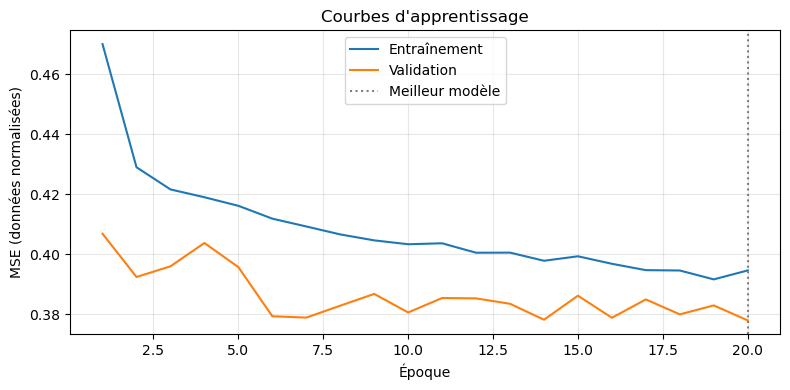

In [35]:
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele_energie.parameters(), lr=0.001)

NB_EPOQUES = 20
meilleure_val = float("inf")
meilleur_etat = None
meilleure_epoque = 0
historique_train, historique_val = [], []

for epoque in range(1, NB_EPOQUES + 1):
    # ---- Entraînement ----
    modele_energie.train()
    total = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        perte = critere(modele_energie(xb), yb)

        optimiseur.zero_grad()
        perte.backward()
        optimiseur.step()

        total += perte.item() * xb.size(0)
    perte_train = total / len(train_loader.dataset)

    # ---- Validation ----
    modele_energie.eval()
    total = 0.0
    with torch.no_grad():
        for xb, yb in val_loader:
            xb, yb = xb.to(device), yb.to(device)
            total += critere(modele_energie(xb), yb).item() * xb.size(0)
    perte_val = total / len(val_loader.dataset)

    historique_train.append(perte_train)
    historique_val.append(perte_val)

    # ---- Conserver le meilleur modèle ----
    marque = ""
    if perte_val < meilleure_val:
        meilleure_val = perte_val
        meilleur_etat = copy.deepcopy(modele_energie.state_dict())
        meilleure_epoque = epoque
        marque = "  <- meilleur"

    print(f"Époque {epoque:2d} | train MSE = {perte_train:.4f} | val MSE = {perte_val:.4f}{marque}")

modele_energie.load_state_dict(meilleur_etat)
print(f"\nMeilleur modèle : époque {meilleure_epoque} (val MSE normalisée = {meilleure_val:.4f})")

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(historique_train) + 1), historique_train, label="Entraînement")
plt.plot(range(1, len(historique_val) + 1), historique_val, label="Validation")
plt.axvline(meilleure_epoque, color="gray", linestyle=":", label="Meilleur modèle")
plt.xlabel("Époque")
plt.ylabel("MSE (données normalisées)")
plt.title("Courbes d'apprentissage")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 4. Évaluation sur le test en kW et comparaison avec les références

In [36]:
modele_energie.eval()
with torch.no_grad():
    predictions_norm = torch.cat(
        [modele_energie(xb.to(device)).cpu() for xb, _ in test_loader]
    ).squeeze(-1).numpy()


def vers_kw(v):
    """Retour à l'échelle originale : valeur * ecart_type + moyenne."""
    return v * ecart_type + moyenne


y_reel = vers_kw(y_test.squeeze(-1).numpy())
y_transformer = vers_kw(predictions_norm)

# Références (calculées sur les mêmes fenêtres que le Transformer)
y_persistance = vers_kw(X_test[:, -1, 0].numpy())   # valeur de l'heure t-1
y_journaliere = vers_kw(X_test[:, 0, 0].numpy())    # valeur de l'heure t-24


def mae(reel, pred):
    return np.mean(np.abs(reel - pred))


def rmse(reel, pred):
    return np.sqrt(np.mean((reel - pred) ** 2))


modeles = {
    "Transformer": y_transformer,
    "Persistance (t-1)": y_persistance,
    "Référence journalière (t-24)": y_journaliere,
}

resultats = pd.DataFrame(
    {
        "MAE (kW)": [mae(y_reel, p) for p in modeles.values()],
        "RMSE (kW)": [rmse(y_reel, p) for p in modeles.values()],
    },
    index=modeles.keys(),
)
display(resultats.round(4))

print("Gain du Transformer (positif = meilleur que la référence) :")
for ref in ["Persistance (t-1)", "Référence journalière (t-24)"]:
    gain_mae = 100 * (1 - resultats.loc["Transformer", "MAE (kW)"] / resultats.loc[ref, "MAE (kW)"])
    gain_rmse = 100 * (1 - resultats.loc["Transformer", "RMSE (kW)"] / resultats.loc[ref, "RMSE (kW)"])
    print(f"  vs {ref:<30s} MAE {gain_mae:+6.1f} %   RMSE {gain_rmse:+6.1f} %")

,MAE (kW),RMSE (kW)
Transformer,0.3539,0.4939
Persistance (t-1),0.3892,0.5884
Référence journalière (t-24),0.5133,0.7639


Gain du Transformer (positif = meilleur que la référence) :
  vs Persistance (t-1)              MAE   +9.1 %   RMSE  +16.1 %
  vs Référence journalière (t-24)   MAE  +31.1 %   RMSE  +35.3 %


### 5. Prédictions et observations sur sept jours consécutifs du test

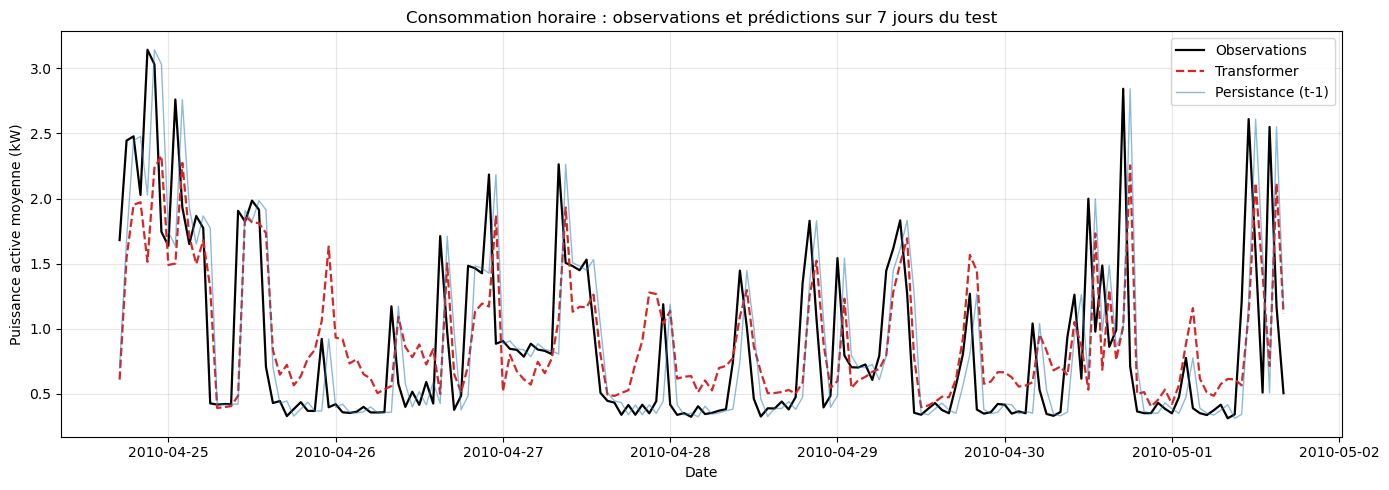

In [37]:
NB_HEURES = 7 * 24

# Chercher le premier bloc de 168 heures consécutives (sans trou dans le test)
saut = np.r_[True, np.diff(temps_test.values) != np.timedelta64(1, "h")]
debuts = np.flatnonzero(saut)
fins = np.r_[debuts[1:], len(temps_test)]
debut = next((d for d, f in zip(debuts, fins) if f - d >= NB_HEURES), 0)
zone = slice(debut, debut + NB_HEURES)

plt.figure(figsize=(14, 5))
plt.plot(temps_test[zone], y_reel[zone], label="Observations", color="black", linewidth=1.6)
plt.plot(temps_test[zone], y_transformer[zone], label="Transformer", color="tab:red",
         linestyle="--", linewidth=1.6)
plt.plot(temps_test[zone], y_persistance[zone], label="Persistance (t-1)", color="tab:blue",
         linewidth=1, alpha=0.5)
plt.title("Consommation horaire : observations et prédictions sur 7 jours du test")
plt.xlabel("Date")
plt.ylabel("Puissance active moyenne (kW)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 6. Questions de réflexion

**Le Transformer améliore-t-il les deux références ?**
La réponse se lit dans le tableau et les gains ci-dessus. Sur cette série, la référence journalière est en général la plus faible : la consommation d'un foyer change beaucoup d'un jour à l'autre (heures de lever, absences, appareils lancés à des heures différentes). La persistance est une référence solide à un horizon d'une heure, car la consommation varie souvent peu d'une heure à la suivante. Le Transformer bat nettement la référence journalière et, le plus souvent, la persistance d'un écart plus modeste (quelques pour cent de MAE). Il combine en effet le niveau récent avec la forme de la journée. Si le gain sur la persistance est faible ou négatif, c'est le signe que 24 valeurs seules donnent peu d'information au-delà de la dernière heure.

**Une fenêtre de 168 heures capture-t-elle mieux les habitudes hebdomadaires ?**
Potentiellement oui. Avec 168 heures, le modèle voit la même heure du même jour la semaine précédente et peut distinguer semaine et week-end, ce qu'une fenêtre de 24 h ne permet pas. En contrepartie, l'attention coûte 168² au lieu de 24² opérations par tête. Il y a aussi plus de fenêtres écartées à cause des valeurs manquantes, plus de bruit à filtrer et plus de positions à apprendre. Le gain n'est donc pas garanti : il faut le mesurer, et comparer aussi avec une référence hebdomadaire (valeur à t-168).

**Intérêt d'ajouter l'heure de la journée et le jour de la semaine ?**
Avec 24 valeurs seules, le modèle ne sait pas explicitement si l'heure à prédire est 7 h (hausse probable) ou 23 h (baisse probable) : il doit le deviner à partir de la forme de la courbe. Ajouter l'heure (encodée en sin/cos pour respecter son caractère cyclique) et le jour de la semaine (one-hot ou embedding) donne ce contexte directement. Le modèle peut alors apprendre les habitudes horaires et l'effet du week-end sans avoir besoin d'une fenêtre de 168 heures. Ces informations sont connues à l'avance pour l'heure cible, donc il n'y a aucune fuite. L'entrée devient `(batch, 24, 1 + k)` avec une projection `Linear(1 + k, 32)`.

**Pourquoi normaliser uniquement à partir de l'entraînement ?**
Pour éviter une fuite d'information. La moyenne et l'écart-type calculés sur toute la série contiennent des informations sur la validation et le test, c'est-à-dire sur le futur. En production, seules les données passées sont connues. Calculer les statistiques sur l'entraînement puis appliquer exactement la même transformation à la validation et au test reproduit cette situation et donne une évaluation honnête.

**Comment prédire une énergie consommée en kWh ?**
L'énergie est égale à la puissance moyenne multipliée par la durée : E (kWh) = P moyenne (kW) × Δt (h). Les mesures brutes sont des puissances moyennes sur une minute, donc chaque minute représente P/60 kWh. L'énergie d'une heure vaut la somme des puissances minute divisée par 60, ce qui revient à la puissance moyenne horaire × 1 h. Pour une heure complète, la valeur numérique est donc la même : seule l'unité change. En pratique :
- utiliser `resample("h").sum() / 60` et ne garder que les heures complètes (ou corriger les minutes manquantes avec `moyenne × 1 h` quand au moins 45 minutes sont présentes) ;
- pour une cible journalière, sommer les kWh horaires avec `resample("D").sum()` et adapter la fenêtre et l'horizon ;
- exprimer la MAE et la RMSE en kWh.

## Exercice 2 — Mini-GPT pour générer du texte

Transformer autorégressif entraîné depuis zéro, avec une tokenisation par caractères.

In [38]:
import os
import numpy as np
import torch
import torch.nn as nn

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Créer un petit corpus si corpus.txt n'existe pas encore.
# (Plus le texte est long, meilleure est la génération : tu peux le remplacer par tes propres pages.)
TEXTE_CORPUS = """La ville se réveille lentement. Les premiers bus traversent les avenues encore vides, et les boulangers ouvrent leurs portes. L'odeur du pain chaud se mélange à celle du café. Sur la place, un vieil homme nourrit les pigeons pendant que les enfants partent à l'école avec leurs cartables sur le dos.

Au bord de la mer, le vent souffle fort. Les vagues frappent les rochers et laissent derrière elles une écume blanche. Les pêcheurs reviennent au port avec leurs filets pleins. Ils vendent les poissons sur le quai, et les clients discutent des prix en riant. Le soleil monte dans le ciel et la lumière devient plus douce.

Dans la bibliothèque, le silence est presque total. Une étudiante lit un livre de mathématiques et prend des notes dans son cahier. Elle veut comprendre comment les machines apprennent à partir des données. Elle découvre les réseaux de neurones, les fonctions de perte et la descente de gradient. Chaque page lui pose une nouvelle question, et chaque réponse lui donne envie de continuer.

Le soir, la famille se retrouve autour de la table. La mère prépare un tajine aux légumes, le père sert le thé à la menthe, et les enfants racontent leur journée. On parle de l'école, du travail, des voisins et des projets pour les vacances. Après le repas, tout le monde regarde le ciel étoilé depuis la terrasse.

Un modèle de langage apprend à prédire le caractère suivant. Il lit un texte, regarde les caractères précédents et calcule une probabilité pour chaque caractère possible. Au début, ses prédictions sont mauvaises. Puis, après de nombreux exemples, il apprend les mots les plus fréquents, les espaces, la ponctuation et même quelques règles de grammaire.

Le printemps arrive avec ses couleurs. Les arbres se couvrent de feuilles, les fleurs s'ouvrent dans les jardins, et les oiseaux chantent dès le matin. Les gens sortent plus souvent, marchent dans les parcs et s'assoient sur les bancs pour profiter du soleil. Les journées deviennent plus longues et plus chaudes.

En été, la chaleur devient forte. Les familles partent à la plage ou à la montagne. Les enfants nagent, construisent des châteaux de sable et mangent des glaces. Le soir, les terrasses des cafés sont pleines, et la musique résonne dans les rues jusqu'à minuit.

L'automne apporte la pluie et le vent. Les feuilles tombent des arbres et couvrent les trottoirs. Les étudiants reprennent les cours, les professeurs préparent leurs leçons, et la ville retrouve son rythme habituel. On boit des boissons chaudes et on lit des livres près de la fenêtre.

L'hiver, les nuits sont longues et froides. Dans les montagnes, la neige couvre les routes et les villages. Les habitants allument le feu dans la cheminée et racontent de vieilles histoires. Les enfants écoutent avec attention, puis s'endorment en rêvant de voyages lointains.

Le train quitte la gare à huit heures. Par la fenêtre, les voyageurs voient défiler les champs, les rivières et les petites maisons blanches. Certains lisent, d'autres dorment ou regardent le paysage. Une femme écrit une lettre à sa sœur pour lui raconter son voyage. Quand le train arrive enfin, le soleil se couche sur la ville et les lumières s'allument une à une.
"""

if not os.path.exists("corpus.txt"):
    with open("corpus.txt", "w", encoding="utf-8") as fichier:
        fichier.write(TEXTE_CORPUS)
    print("corpus.txt créé.")

# --------------------------------------------------
# Vocabulaire par caractères (code de l'énoncé)
# --------------------------------------------------
with open("corpus.txt", encoding="utf-8") as fichier:
    texte = fichier.read()

caracteres = sorted(set(texte))
stoi = {c: i for i, c in enumerate(caracteres)}
itos = {i: c for c, i in stoi.items()}

tokens = torch.tensor([stoi[c] for c in texte], dtype=torch.long)
taille_vocab_car = len(caracteres)

print("Nombre de caractères du corpus :", len(texte))
print("Taille du vocabulaire          :", taille_vocab_car)

# Exemple d'une paire entrée/cible : la cible est décalée d'un caractère
longueur = 64
x = tokens[:longueur]
y = tokens[1:longueur + 1]
print("\nEntrée :", repr("".join(itos[i] for i in x[:20].tolist())))
print("Cible  :", repr("".join(itos[i] for i in y[:20].tolist())))

# Découpage 90 % entraînement / 10 % validation
n_train_car = int(0.9 * len(tokens))
donnees_train = tokens[:n_train_car]
donnees_val = tokens[n_train_car:]


def lot_texte(donnees, taille_lot=32):
    """Tire des séquences aléatoires de 64 caractères et leurs cibles décalées."""
    debuts = torch.randint(0, len(donnees) - longueur - 1, (taille_lot,))
    xb = torch.stack([donnees[d:d + longueur] for d in debuts])
    yb = torch.stack([donnees[d + 1:d + longueur + 1] for d in debuts])
    return xb.to(device), yb.to(device)

corpus.txt créé.
Nombre de caractères du corpus : 3194
Taille du vocabulaire          : 46

Entrée : 'La ville se réveille'
Cible  : 'a ville se réveille '


### 1–2. Bloc GPT (pre-LayerNorm, attention causale, MLP 64 → 256 → 64) et modèle

In [39]:
class BlocGPT(nn.Module):
    def __init__(self, d_model=64, nb_tetes=4, d_cache=256, dropout=0.1):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attention = nn.MultiheadAttention(
            d_model, nb_tetes, dropout=dropout, batch_first=True
        )
        self.norm2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, d_cache),   # 64 -> 256
            nn.GELU(),
            nn.Linear(d_cache, d_model),   # 256 -> 64
            nn.Dropout(dropout),
        )

    def forward(self, x):
        T = x.shape[1]

        # True signifie : cette relation d'attention est interdite (futur)
        masque = torch.triu(
            torch.ones(T, T, dtype=torch.bool, device=x.device),
            diagonal=1,
        )

        # 1) LayerNorm avant l'attention + attention causale + résiduelle
        h = self.norm1(x)
        attention, _ = self.attention(h, h, h, attn_mask=masque, need_weights=False)
        x = x + attention

        # 2) Seconde LayerNorm + MLP + résiduelle
        x = x + self.mlp(self.norm2(x))
        return x


class MiniGPT(nn.Module):
    def __init__(self, taille_vocab, longueur_max=64, d_model=64, nb_tetes=4,
                 nb_blocs=2, dropout=0.1):
        super().__init__()
        self.longueur_max = longueur_max
        self.emb_tokens = nn.Embedding(taille_vocab, d_model)
        self.emb_positions = nn.Embedding(longueur_max, d_model)
        self.blocs = nn.ModuleList(
            [BlocGPT(d_model, nb_tetes, 4 * d_model, dropout) for _ in range(nb_blocs)]
        )
        self.norm_finale = nn.LayerNorm(d_model)
        self.tete = nn.Linear(d_model, taille_vocab)   # projection vers le vocabulaire

    def forward(self, ids, retour_representations=False):
        # ids : (batch, T)
        T = ids.shape[1]
        positions = torch.arange(T, device=ids.device)

        h = self.emb_tokens(ids) + self.emb_positions(positions).unsqueeze(0)  # (batch, T, 64)
        for bloc in self.blocs:
            h = bloc(h)
        h = self.norm_finale(h)

        logits = self.tete(h)                                                  # (batch, T, vocab)
        if retour_representations:
            return logits, h
        return logits


gpt = MiniGPT(taille_vocab_car, longueur_max=longueur).to(device)

# Vérification des formes
xb, yb = lot_texte(donnees_train, taille_lot=8)
with torch.no_grad():
    logits, representations = gpt(xb, retour_representations=True)

print("Identifiants en entrée :", tuple(xb.shape))
print("Représentations        :", tuple(representations.shape))
print("Logits                 :", tuple(logits.shape))
print("Cibles                 :", tuple(yb.shape))
print("Nombre de paramètres   :", sum(p.numel() for p in gpt.parameters()))

Identifiants en entrée : (8, 64)
Représentations        : (8, 64, 64)
Logits                 : (8, 64, 46)
Cibles                 : (8, 64)
Nombre de paramètres   : 110126


### Vérification essentielle : causalité

In [40]:
# En mode eval(), modifier un caractère futur ne doit pas modifier les logits des positions précédentes.
gpt.eval()

ids = xb[:1].clone()
k = 40                                  # position du caractère modifié
ids_modifie = ids.clone()
ids_modifie[0, k] = (ids[0, k] + 1) % taille_vocab_car

with torch.no_grad():
    logits_a = gpt(ids)
    logits_b = gpt(ids_modifie)

ecart_avant = (logits_a[:, :k] - logits_b[:, :k]).abs().max().item()
ecart_apres = (logits_a[:, k:] - logits_b[:, k:]).abs().max().item()

print(f"Écart max sur les positions < {k}  : {ecart_avant:.2e}  (doit être ~0)")
print(f"Écart max sur les positions >= {k} : {ecart_apres:.2e}  (doit être > 0)")
print("Causalité respectée :", torch.allclose(logits_a[:, :k], logits_b[:, :k], atol=1e-5))

Écart max sur les positions < 40  : 0.00e+00  (doit être ~0)
Écart max sur les positions >= 40 : 1.58e+00  (doit être > 0)
Causalité respectée : True


### 3. Entraînement (entropie croisée sur toutes les positions)

In [41]:
torch.manual_seed(42)
gpt = MiniGPT(taille_vocab_car, longueur_max=longueur).to(device)

optim_gpt = torch.optim.AdamW(gpt.parameters(), lr=1e-3)
critere_gpt = nn.CrossEntropyLoss()

NB_ITERATIONS = 2000


@torch.no_grad()
def perte_validation(nb_lots=20):
    gpt.eval()
    pertes = []
    for _ in range(nb_lots):
        xv, yv = lot_texte(donnees_val)
        logits = gpt(xv)
        pertes.append(critere_gpt(logits.reshape(-1, taille_vocab_car), yv.reshape(-1)).item())
    return float(np.mean(pertes))


for iteration in range(1, NB_ITERATIONS + 1):
    gpt.train()
    xb, yb = lot_texte(donnees_train)

    logits = gpt(xb)                                        # (batch, 64, vocab)
    perte = critere_gpt(
        logits.reshape(-1, taille_vocab_car),               # (batch*64, vocab)
        yb.reshape(-1),                                     # (batch*64,)
    )

    optim_gpt.zero_grad()
    perte.backward()
    torch.nn.utils.clip_grad_norm_(gpt.parameters(), 1.0)
    optim_gpt.step()

    if iteration == 1 or iteration % 200 == 0:
        print(f"Itération {iteration:4d} | train = {perte.item():.3f} | val = {perte_validation():.3f}")

Itération    1 | train = 3.948 | val = 3.872
Itération  200 | train = 2.111 | val = 2.316
Itération  400 | train = 1.764 | val = 2.290
Itération  600 | train = 1.373 | val = 2.306
Itération  800 | train = 0.978 | val = 2.640
Itération 1000 | train = 0.678 | val = 3.105
Itération 1200 | train = 0.443 | val = 3.614
Itération 1400 | train = 0.380 | val = 3.853
Itération 1600 | train = 0.311 | val = 4.205
Itération 1800 | train = 0.298 | val = 4.433
Itération 2000 | train = 0.233 | val = 4.560


### 4–5. Génération de 200 caractères et comparaison des températures

In [42]:
@torch.no_grad()
def generer(modele, amorce, nb_caracteres=200, temperature=1.0):
    modele.eval()
    ids = torch.tensor([[stoi[c] for c in amorce if c in stoi]], dtype=torch.long, device=device)

    for _ in range(nb_caracteres):
        contexte = ids[:, -modele.longueur_max:]            # au plus 64 caractères
        logits = modele(contexte)[:, -1, :]                 # logits du dernier caractère
        probabilites = torch.softmax(logits / temperature, dim=-1)
        suivant = torch.multinomial(probabilites, num_samples=1)   # échantillonnage
        ids = torch.cat([ids, suivant], dim=1)

    return "".join(itos[i] for i in ids[0].tolist())


amorce = "Le soir, "
for temperature in [0.5, 1.0, 1.5]:
    torch.manual_seed(0)
    print(f"========== Température {temperature} ==========")
    print(generer(gpt, amorce, nb_caracteres=200, temperature=temperature))
    print()

========== Température 0.5 ==========
Le soir, la famille se retrouve son rythme habituel. On boit des boissons chaudes et on lit des livres près de la fenêtre.

L'hiver, les nuits sont longues et froides. Dans les montagnes, la neige couvre les r

========== Température 1.0 ==========
Le soir, la famille se retrouve son rythme habituel. On boit des boissons chaudes et on lit des livres près de la fenêtre.

Un modèle de langage apprend à pre la place, un vieil homme nourrit devieilles hances

========== Température 1.5 ==========
Le soir, la famille se retrouve son rythme habituel. Les prédictédes cala sur le du chante. Il livres preprennent les cours, les professeurs préparent leurs leçons, et la ville retrouve sonthme nuit la Le gles



### Questions

**Que se passe-t-il pendant l'entraînement si le masque causal est supprimé ?**
Chaque position peut alors regarder les caractères suivants, y compris celui qu'elle doit prédire. Le modèle apprend à recopier la réponse : la perte d'entraînement chute presque à zéro, mais c'est une fuite d'information. Pendant la génération, le futur n'existe pas encore, donc ce raccourci disparaît et le modèle produit du texte incohérent. Le test de causalité ci-dessus échouerait aussi.

**Quel effet la température a-t-elle sur la génération ?**
Les logits sont divisés par la température avant le softmax :
- **T < 1 (0.5)** : la distribution devient plus pointue. Le texte est plus prudent, plus proche du corpus, mais plus répétitif.
- **T = 1** : on échantillonne la distribution apprise telle quelle.
- **T > 1 (1.5)** : la distribution s'aplatit. Le texte est plus varié, mais contient plus de fautes, de mots inventés et de caractères aléatoires.

**Pourquoi faut-il décaler les cibles d'une position ?**
La tâche est de prédire le caractère suivant : la position t doit prédire le caractère t+1. Sans décalage, la cible serait le caractère d'entrée lui-même, que le modèle voit déjà : il apprendrait juste à le recopier. Le décalage permet aussi d'entraîner en parallèle 64 prédictions « caractère suivant » à partir d'une seule séquence (teacher forcing), grâce au masque causal.

## Exercice 3 — Mini-BERT pour retrouver des mots masqués

Transformer bidirectionnel entraîné avec l'objectif de modélisation du langage masqué (MLM).

In [43]:
import random
from collections import Counter

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

random.seed(42)
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PAD, UNK, CLS, SEP, MASK = 0, 1, 2, 3, 4
SPECIAUX = ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"]
NB_SPECIAUX = len(SPECIAUX)
LONGUEUR_MAX = 32

# --------------------------------------------------
# Petit corpus de phrases (généré à partir de modèles de phrases)
# --------------------------------------------------
sujets = [
    "le chat", "le chien", "le garçon", "la fille", "mon frère", "ma sœur",
    "le professeur", "la voisine", "notre ami", "le bébé",
]
actions = {
    "dort": ["sur le canapé", "dans la chambre", "sous la table", "près de la fenêtre"],
    "mange": ["une pomme", "du pain", "une orange", "des légumes", "du riz"],
    "lit": ["un livre", "le journal", "une lettre", "un roman"],
    "joue": ["dans le jardin", "avec le ballon", "au parc", "avec ses amis"],
    "regarde": ["la télévision", "le ciel", "la mer", "un film"],
    "boit": ["du lait", "de l eau", "du thé", "un jus"],
}
moments = ["", "le matin", "le soir", "tous les jours", "aujourd hui", "souvent"]

phrases = [
    f"{sujet} {verbe} {complement} {moment}".strip()
    for sujet in sujets
    for verbe, complements in actions.items()
    for complement in complements
    for moment in moments
]
random.shuffle(phrases)

n_val = int(0.15 * len(phrases))
phrases_val = phrases[:n_val]
phrases_train = phrases[n_val:]

print("Phrases d'entraînement :", len(phrases_train))
print("Phrases de validation  :", len(phrases_val))
print("Exemple                :", phrases_train[0])

# --------------------------------------------------
# 1. Vocabulaire construit sur l'entraînement, encodage et padding à 32 tokens
# --------------------------------------------------
compteur = Counter(mot for phrase in phrases_train for mot in phrase.split())
vocab = SPECIAUX + sorted(compteur)
mot2id = {mot: i for i, mot in enumerate(vocab)}
id2mot = {i: mot for mot, i in mot2id.items()}
taille_vocabulaire = len(vocab)


def encoder(phrase):
    """[CLS] mots ... [SEP] [PAD] ... (32 tokens)"""
    ids = [CLS] + [mot2id.get(mot, UNK) for mot in phrase.split()][:LONGUEUR_MAX - 2] + [SEP]
    return ids + [PAD] * (LONGUEUR_MAX - len(ids))


ids_train = torch.tensor([encoder(p) for p in phrases_train], dtype=torch.long)
ids_val = torch.tensor([encoder(p) for p in phrases_val], dtype=torch.long)

print("\nTaille du vocabulaire :", taille_vocabulaire)
print("ids_train :", tuple(ids_train.shape))
print("Phrase encodée :", " ".join(id2mot[i] for i in ids_train[0].tolist()[:14]), "...")

Phrases d'entraînement : 1275
Phrases de validation  : 225
Exemple                : la voisine mange des légumes le soir

Taille du vocabulaire : 72
ids_train : (1275, 32)
Phrase encodée : [CLS] la voisine mange des légumes le soir [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] ...


### 2. Sélection de 15 % des tokens ordinaires (80 % [MASK], 10 % aléatoire, 10 % inchangé)

In [44]:
def masquer(input_ids, proportion=0.15, generateur=None):
    """
    Retourne :
      - entree_corrompue : séquences après corruption
      - labels           : token original aux positions sélectionnées, -100 ailleurs
      - selection        : masque booléen des positions à prédire
    """
    ordinaires = input_ids >= NB_SPECIAUX          # exclut PAD, UNK, CLS, SEP, MASK

    # Sélection aléatoire de 15 % des tokens ordinaires
    tirage = torch.rand(input_ids.shape, generator=generateur)
    selection = (tirage < proportion) & ordinaires

    # Au moins une position sélectionnée par phrase contenant des tokens ordinaires
    sans_selection = (~selection.any(dim=1)) & ordinaires.any(dim=1)
    lignes = torch.nonzero(sans_selection).flatten()
    if len(lignes) > 0:
        bruit = torch.rand(input_ids.shape, generator=generateur).masked_fill(~ordinaires, -1.0)
        selection[lignes, bruit[lignes].argmax(dim=1)] = True

    # Répartition 80 / 10 / 10
    choix = torch.rand(input_ids.shape, generator=generateur)
    a_masquer = selection & (choix < 0.8)
    a_remplacer = selection & (choix >= 0.8) & (choix < 0.9)
    # les 10 % restants (choix >= 0.9) sont conservés inchangés

    entree_corrompue = input_ids.clone()
    entree_corrompue[a_masquer] = MASK
    aleatoires = torch.randint(NB_SPECIAUX, taille_vocabulaire, input_ids.shape, generator=generateur)
    entree_corrompue[a_remplacer] = aleatoires[a_remplacer]

    # Préparation des cibles (énoncé) : la perte ne porte que sur les positions sélectionnées
    labels = input_ids.clone()
    labels[~selection] = -100

    return entree_corrompue, labels, selection


# Illustration
corrompu, labels_demo, selection_demo = masquer(ids_train[:3])
for i in range(3):
    n_mots = int((ids_train[i] != PAD).sum())
    print("Original :", " ".join(id2mot[t] for t in ids_train[i, :n_mots].tolist()))
    print("Corrompu :", " ".join(id2mot[t] for t in corrompu[i, :n_mots].tolist()))
    print("Positions sélectionnées :", torch.nonzero(selection_demo[i]).flatten().tolist())
    print()

Original : [CLS] la voisine mange des légumes le soir [SEP]
Corrompu : [CLS] la voisine mange des [MASK] le soir [SEP]
Positions sélectionnées : [5]

Original : [CLS] le professeur regarde la télévision le matin [SEP]
Corrompu : [CLS] le chambre regarde la télévision le matin [SEP]
Positions sélectionnées : [2]

Original : [CLS] le professeur joue au parc le soir [SEP]
Corrompu : [CLS] le professeur joue au parc le [MASK] [SEP]
Positions sélectionnées : [7]



### 3. Modèle mini-BERT (attention bidirectionnelle + masque de padding)

In [45]:
class MiniBERT(nn.Module):
    def __init__(self, taille_vocab, longueur_max=32, d_model=64, nb_tetes=4,
                 nb_couches=2, dim_ff=256, dropout=0.1):
        super().__init__()
        self.emb_tokens = nn.Embedding(taille_vocab, d_model, padding_idx=PAD)
        self.emb_positions = nn.Embedding(longueur_max, d_model)
        self.norm = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

        couche = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nb_tetes,
            dim_feedforward=dim_ff,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(
            couche, num_layers=nb_couches, enable_nested_tensor=False
        )
        self.tete = nn.Linear(d_model, taille_vocab)   # projection vers le vocabulaire

    def forward(self, ids, masque_padding):
        # ids : (batch, 32) ; masque_padding : (batch, 32), True = position [PAD] ignorée
        positions = torch.arange(ids.shape[1], device=ids.device)
        h = self.emb_tokens(ids) + self.emb_positions(positions).unsqueeze(0)
        h = self.dropout(self.norm(h))

        # Aucun masque causal : chaque token voit le contexte à gauche ET à droite
        h = self.encodeur(h, src_key_padding_mask=masque_padding)   # (batch, 32, 64)
        return self.tete(h)                                           # (batch, 32, vocab)


bert = MiniBERT(taille_vocabulaire, LONGUEUR_MAX).to(device)

with torch.no_grad():
    logits_demo = bert(ids_train[:8].to(device), (ids_train[:8] == PAD).to(device))
print("Entrée :", tuple(ids_train[:8].shape))
print("Logits :", tuple(logits_demo.shape))
print("Nombre de paramètres :", sum(p.numel() for p in bert.parameters()))

Entrée : (8, 32)
Logits : (8, 32, 72)
Nombre de paramètres : 111432


### 4–5. Entraînement (perte sur les positions sélectionnées) et exactitude en validation

In [46]:
torch.manual_seed(42)
bert = MiniBERT(taille_vocabulaire, LONGUEUR_MAX).to(device)
optim_bert = torch.optim.AdamW(bert.parameters(), lr=1e-3)
critere = torch.nn.CrossEntropyLoss(ignore_index=-100)

loader_bert = DataLoader(TensorDataset(ids_train), batch_size=64, shuffle=True)

# Validation : masquage fixe pour comparer les époques entre elles
generateur_val = torch.Generator().manual_seed(123)
val_corrompu, val_labels, val_selection = masquer(ids_val, generateur=generateur_val)
val_masque_pad = ids_val == PAD


@torch.no_grad()
def evaluer_bert():
    bert.eval()
    logits = bert(val_corrompu.to(device), val_masque_pad.to(device))
    perte = critere(logits.reshape(-1, taille_vocabulaire), val_labels.to(device).reshape(-1)).item()
    predictions = logits.argmax(dim=-1).cpu()
    exactitude = (predictions[val_selection] == ids_val[val_selection]).float().mean().item()
    return perte, exactitude


NB_EPOQUES_BERT = 40
for epoque in range(1, NB_EPOQUES_BERT + 1):
    bert.train()
    total, nb = 0.0, 0
    for (input_ids,) in loader_bert:
        # Nouveau masquage à chaque passage (masquage dynamique)
        entree, labels, _ = masquer(input_ids)
        masque_padding = input_ids == PAD

        logits = bert(entree.to(device), masque_padding.to(device))
        loss = critere(
            logits.reshape(-1, taille_vocabulaire),
            labels.to(device).reshape(-1),
        )

        optim_bert.zero_grad()
        loss.backward()
        optim_bert.step()

        total += loss.item()
        nb += 1

    if epoque == 1 or epoque % 5 == 0:
        perte_val, exactitude_val = evaluer_bert()
        print(f"Époque {epoque:2d} | train = {total / nb:.3f} | val = {perte_val:.3f} "
              f"| exactitude val (tokens sélectionnés) = {exactitude_val:.1%}")

perte_val, exactitude_val = evaluer_bert()
print(f"\nExactitude finale sur les tokens sélectionnés de la validation : {exactitude_val:.1%}")

Époque  1 | train = 3.817 | val = 3.236 | exactitude val (tokens sélectionnés) = 21.4%
Époque  5 | train = 2.087 | val = 1.787 | exactitude val (tokens sélectionnés) = 53.1%
Époque 10 | train = 1.078 | val = 0.786 | exactitude val (tokens sélectionnés) = 73.6%
Époque 15 | train = 0.666 | val = 0.532 | exactitude val (tokens sélectionnés) = 83.0%
Époque 20 | train = 0.539 | val = 0.386 | exactitude val (tokens sélectionnés) = 85.8%
Époque 25 | train = 0.454 | val = 0.365 | exactitude val (tokens sélectionnés) = 84.9%
Époque 30 | train = 0.409 | val = 0.362 | exactitude val (tokens sélectionnés) = 84.9%
Époque 35 | train = 0.430 | val = 0.291 | exactitude val (tokens sélectionnés) = 87.1%
Époque 40 | train = 0.400 | val = 0.293 | exactitude val (tokens sélectionnés) = 85.5%

Exactitude finale sur les tokens sélectionnés de la validation : 85.5%


### Trois propositions les plus probables pour quelques mots masqués

In [47]:
@torch.no_grad()
def proposer(phrase, mot_a_masquer, k=3):
    bert.eval()
    mots = phrase.split()
    indice = mots.index(mot_a_masquer)
    ids = torch.tensor([encoder(phrase)], dtype=torch.long)
    position = indice + 1                       # +1 à cause de [CLS]
    ids[0, position] = MASK

    logits = bert(ids.to(device), (ids == PAD).to(device))
    probabilites = torch.softmax(logits[0, position], dim=-1)
    top_p, top_i = probabilites.topk(k)

    affichage = " ".join(mots[:indice] + ["[MASK]"] + mots[indice + 1:])
    print(f"{affichage}   (attendu : {mot_a_masquer})")
    for p, i in zip(top_p, top_i):
        print(f"    {p.item():6.1%}  {id2mot[i.item()]}")
    print()


# Phrases du jeu de validation (jamais vues pendant l'entraînement)
for phrase in phrases_val[:4]:
    mots = [m for m in phrase.split() if m in mot2id]
    proposer(phrase, random.choice(mots))

# Quelques exemples choisis
proposer("le chat dort sur le canapé le soir", "canapé")
proposer("ma sœur mange une pomme le matin", "mange")
proposer("le professeur lit le journal tous les jours", "journal")
proposer("notre ami boit du thé souvent", "thé")

notre ami regarde la télévision le [MASK]   (attendu : matin)
     53.4%  soir
     46.0%  matin
      0.3%  hui

[MASK] garçon joue avec ses amis le matin   (attendu : le)
     99.8%  le
      0.0%  notre
      0.0%  la

[MASK] garçon joue avec le ballon le soir   (attendu : le)
     99.8%  le
      0.1%  notre
      0.0%  la

la fille joue avec [MASK] amis tous les jours   (attendu : ses)
     98.3%  ses
      0.8%  le
      0.3%  parc

le chat dort sur le [MASK] le soir   (attendu : canapé)
     99.7%  canapé
      0.1%  jardin
      0.0%  tous

ma sœur [MASK] une pomme le matin   (attendu : mange)
     99.6%  mange
      0.2%  lit
      0.1%  notre

le professeur lit le [MASK] tous les jours   (attendu : journal)
     98.2%  journal
      0.6%  ciel
      0.3%  livre

notre ami boit du [MASK] souvent   (attendu : thé)
     52.6%  lait
     45.1%  thé
      0.6%  riz



### Vérification essentielle : le padding n'influence pas les tokens utiles

In [48]:
# Changer les valeurs aux positions de padding, en gardant le même masque de padding,
# ne doit pas modifier les prédictions des tokens utiles en mode eval().
bert.eval()

entree = val_corrompu[:16].clone()
masque_padding = ids_val[:16] == PAD

entree_modifiee = entree.clone()
aleatoires = torch.randint(NB_SPECIAUX, taille_vocabulaire, entree.shape)
entree_modifiee[masque_padding] = aleatoires[masque_padding]

with torch.no_grad():
    logits_a = bert(entree.to(device), masque_padding.to(device))
    logits_b = bert(entree_modifiee.to(device), masque_padding.to(device))

utiles = ~masque_padding.to(device)
ecart = (logits_a[utiles] - logits_b[utiles]).abs().max().item()
print(f"Écart max sur les tokens utiles : {ecart:.2e}  (doit être ~0)")
print("Padding sans effet :", torch.allclose(logits_a[utiles], logits_b[utiles], atol=1e-5))

Écart max sur les tokens utiles : 0.00e+00  (doit être ~0)
Padding sans effet : True


### Questions

**Pourquoi BERT peut-il utiliser le contexte à droite du mot masqué ?**
C'est un encodeur sans masque causal : chaque position voit toutes les autres positions non masquées par le padding, à gauche comme à droite. Le mot à prédire est caché dans l'entrée (remplacé par [MASK], par un mot aléatoire, ou laissé tel quel sans que le modèle sache lequel). Il n'y a donc pas de fuite, et le modèle peut exploiter tout le contexte de la phrase.

**Pourquoi calculer la perte uniquement sur les positions sélectionnées ?**
Aux autres positions, le modèle voit le bon token dans son entrée : les prédire reviendrait à recopier, ce qui n'apprend rien et noierait le signal utile dans la perte. Le signal d'apprentissage vient de la reconstruction de l'information cachée. On inclut aussi les 10 % de positions conservées inchangées : le modèle ne sait pas quels tokens visibles sont à vérifier, ce qui l'oblige à construire de bonnes représentations pour tous les mots. Cela limite aussi l'écart avec l'utilisation réelle, où [MASK] n'apparaît jamais. Les 10 % remplacés au hasard lui apprennent en plus à ne pas faire une confiance aveugle à l'entrée.

**Pourquoi ce modèle ne génère-t-il pas directement du texte comme GPT ?**
GPT apprend p(token suivant | tokens précédents), ce qui permet d'écrire de gauche à droite en ajoutant un token à la fois. BERT apprend p(token masqué | contexte gauche et droit) : il n'a jamais appris à prolonger un texte. Pour générer, il faudrait fixer la longueur à l'avance, remplir des [MASK] puis raffiner de façon itérative. Cette procédure est coûteuse, ne correspond pas à son entraînement et donne de moins bons résultats. BERT sert plutôt à produire des représentations (classification, extraction, similarité).